# Task
Analyze and forecast hourly energy consumption from "PJMW_MW_Hourly.xlsx" by loading and inspecting the data, performing feature engineering to extract time-based features, analyzing hourly, daily, and seasonal trends through visualizations, preparing data for forecasting by splitting it into training and testing sets (last year for testing), developing and training a suitable time series forecasting model, evaluating its performance, generating a 30-day forecast, visualizing the historical data, predictions, and forecast, and finally, summarizing the key findings and providing an interpretation of the results.

## Load and Inspect Data

### Subtask:
Load the 'PJMW_MW_Hourly.xlsx' dataset into a pandas DataFrame. Inspect the data types, check for any missing values, and ensure the timestamp column is correctly parsed to a datetime format.


**Reasoning**:
The subtask requires loading the Excel file, inspecting its initial rows and data types, and checking for missing values. This step will perform all these initial data loading and inspection tasks.



In [ ]:
import pandas as pd

df = pd.read_excel('/content/PJMW_MW_Hourly.xlsx')

print("First 5 rows of the DataFrame:")
print(df.head())

print("\nDataFrame Info:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

First 5 rows of the DataFrame:
             Datetime  PJMW_MW
0 2002-12-31 01:00:00     5077
1 2002-12-31 02:00:00     4939
2 2002-12-31 03:00:00     4885
3 2002-12-31 04:00:00     4857
4 2002-12-31 05:00:00     4930

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB

Missing values per column:
Datetime    0
PJMW_MW     0
dtype: int64


**Reasoning**:
The 'Datetime' column has been identified as the timestamp and is already in datetime format. The next step is to set this column as the DataFrame's index, as required by the subtask.



In [ ]:
df = df.set_index('Datetime')

print("DataFrame after setting 'Datetime' as index:")
print(df.head())

DataFrame after setting 'Datetime' as index:
                     PJMW_MW
Datetime                    
2002-12-31 01:00:00     5077
2002-12-31 02:00:00     4939
2002-12-31 03:00:00     4885
2002-12-31 04:00:00     4857
2002-12-31 05:00:00     4930


## Feature Engineering for Time Series

### Subtask:
Extract relevant time-based features from the datetime index, such as hour of the day, day of the week, month, and year. Also, create features that indicate seasonal periods (e.g., 'quarter', 'is_summer', 'is_winter') to capture seasonal trends.


**Reasoning**:
The subtask requires extracting several time-based features from the 'Datetime' index. This step will extract 'hour', 'dayofweek', 'month', 'year', 'quarter', and 'is_weekend' and add them as new columns to the DataFrame.



In [ ]:
df['hour'] = df.index.hour
df['dayofweek'] = df.index.dayofweek
df['month'] = df.index.month
df['year'] = df.index.year
df['quarter'] = df.index.quarter
df['is_weekend'] = (df.index.dayofweek == 5) | (df.index.dayofweek == 6)

print("DataFrame with new time-based features:")
print(df.head())

DataFrame with new time-based features:
                     PJMW_MW  hour  dayofweek  month  year  quarter  \
Datetime                                                              
2002-12-31 01:00:00     5077     1          1     12  2002        4   
2002-12-31 02:00:00     4939     2          1     12  2002        4   
2002-12-31 03:00:00     4885     3          1     12  2002        4   
2002-12-31 04:00:00     4857     4          1     12  2002        4   
2002-12-31 05:00:00     4930     5          1     12  2002        4   

                     is_weekend  
Datetime                         
2002-12-31 01:00:00       False  
2002-12-31 02:00:00       False  
2002-12-31 03:00:00       False  
2002-12-31 04:00:00       False  
2002-12-31 05:00:00       False  


**Reasoning**:
To further capture seasonal trends as per the subtask, 'is_summer' and 'is_winter' boolean features need to be created based on the 'month' column.



In [ ]:
df['is_summer'] = (df.index.month >= 6) & (df.index.month <= 8)
df['is_winter'] = (df.index.month == 12) | (df.index.month == 1) | (df.index.month == 2)

print("DataFrame with new seasonal features:")
print(df.head())

DataFrame with new seasonal features:
                     PJMW_MW  hour  dayofweek  month  year  quarter  \
Datetime                                                              
2002-12-31 01:00:00     5077     1          1     12  2002        4   
2002-12-31 02:00:00     4939     2          1     12  2002        4   
2002-12-31 03:00:00     4885     3          1     12  2002        4   
2002-12-31 04:00:00     4857     4          1     12  2002        4   
2002-12-31 05:00:00     4930     5          1     12  2002        4   

                     is_weekend  is_summer  is_winter  
Datetime                                               
2002-12-31 01:00:00       False      False       True  
2002-12-31 02:00:00       False      False       True  
2002-12-31 03:00:00       False      False       True  
2002-12-31 04:00:00       False      False       True  
2002-12-31 05:00:00       False      False       True  


## Analyze Hourly, Daily, and Seasonal Trends

### Subtask:
Visualize hourly and daily energy consumption patterns. Specifically, create plots to show: 1. Average energy consumption by hour of the day. 2. Average energy consumption by day of the week. 3. How daily trends change between different seasons (e.g., comparing hourly averages in summer vs. winter). Ensure all plots include appropriate legends and labels for clarity.


**Reasoning**:
The subtask requires visualizing hourly and daily energy consumption patterns, as well as seasonal trends. I will import the necessary libraries, then calculate and plot the average energy consumption by hour of the day, by day of the week, and finally compare hourly averages between summer and winter.



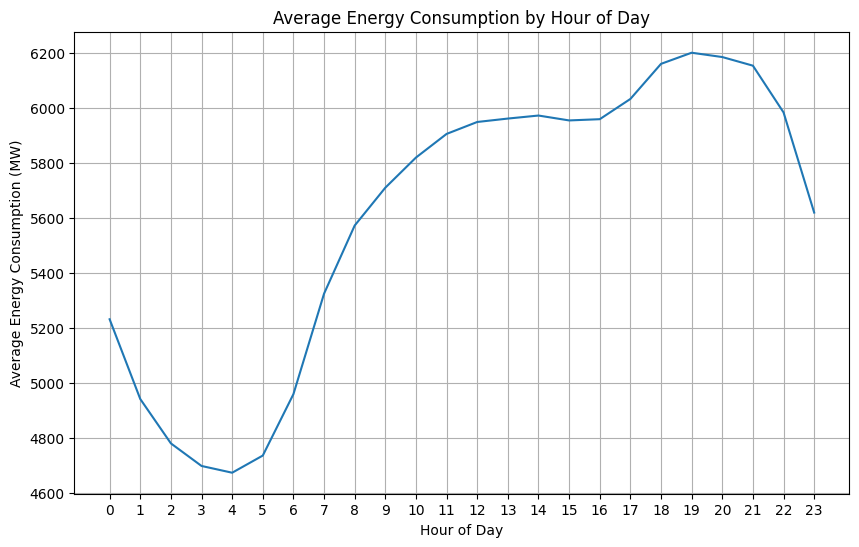

/tmp/ipython-input-1694313579.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=daily_avg.index, y=daily_avg.values, palette='viridis')


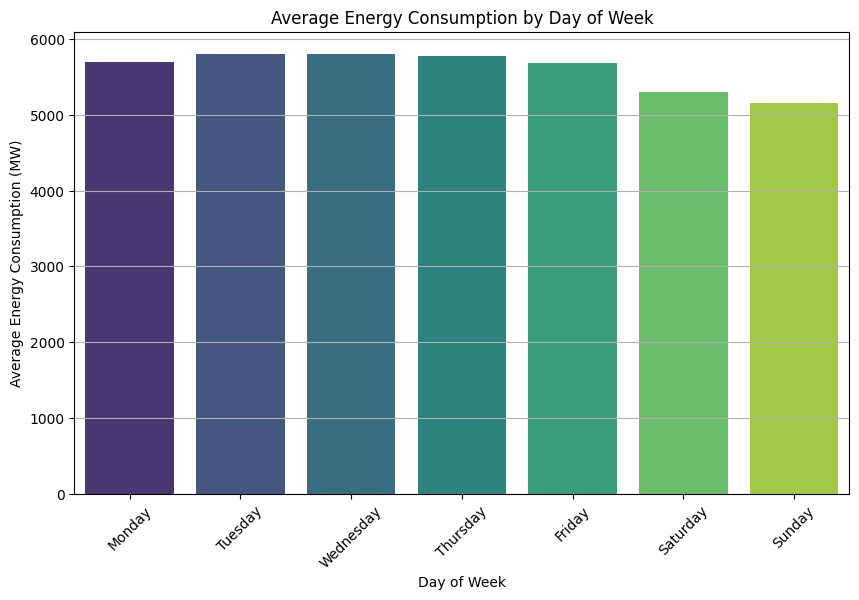

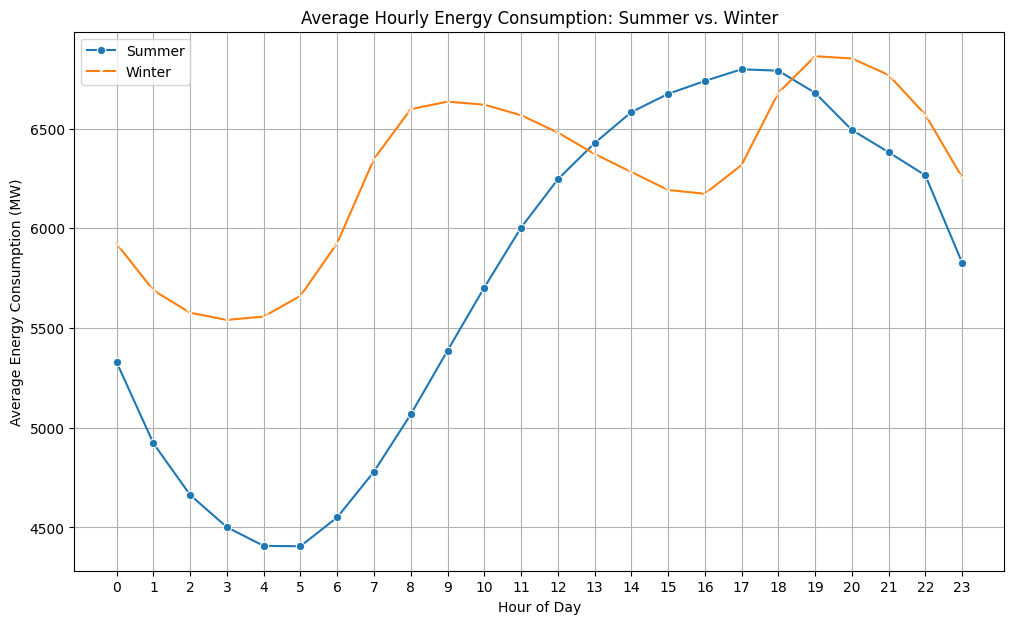

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Average energy consumption by hour of the day
hourly_avg = df.groupby('hour')['PJMW_MW'].mean()

plt.figure(figsize=(10, 6))
sns.lineplot(x=hourly_avg.index, y=hourly_avg.values)
plt.title('Average Energy Consumption by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

# 2. Average energy consumption by day of the week
daily_avg = df.groupby('dayofweek')['PJMW_MW'].mean()

day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(10, 6))
sns.barplot(x=daily_avg.index, y=daily_avg.values, palette='viridis')
plt.title('Average Energy Consumption by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Energy Consumption (MW)')
plt.xticks(ticks=range(7), labels=day_names, rotation=45)
plt.grid(axis='y')
plt.show()

# 3. How daily trends change between different seasons (e.g., comparing hourly averages in summer vs. winter)
summer_hourly_avg = df[df['is_summer']].groupby('hour')['PJMW_MW'].mean()
winter_hourly_avg = df[df['is_winter']].groupby('hour')['PJMW_MW'].mean()

plt.figure(figsize=(12, 7))
sns.lineplot(x=summer_hourly_avg.index, y=summer_hourly_avg.values, label='Summer', marker='o')
sns.lineplot(x=winter_hourly_avg.index, y=winter_hourly_avg.values, label='Winter', marker='x')
plt.title('Average Hourly Energy Consumption: Summer vs. Winter')
plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True)
plt.show()

**Reasoning**:
The previous code produced a `FutureWarning` from seaborn when using `palette` without `hue` in `sns.barplot`. To address this, I will explicitly set the `hue` argument to `daily_avg.index` and `legend=False` to maintain the desired aesthetic while complying with the recommended usage.



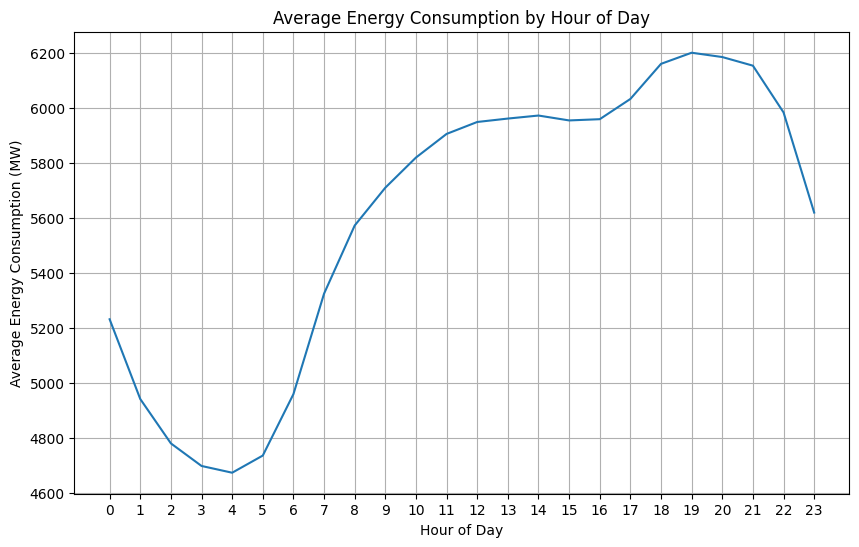

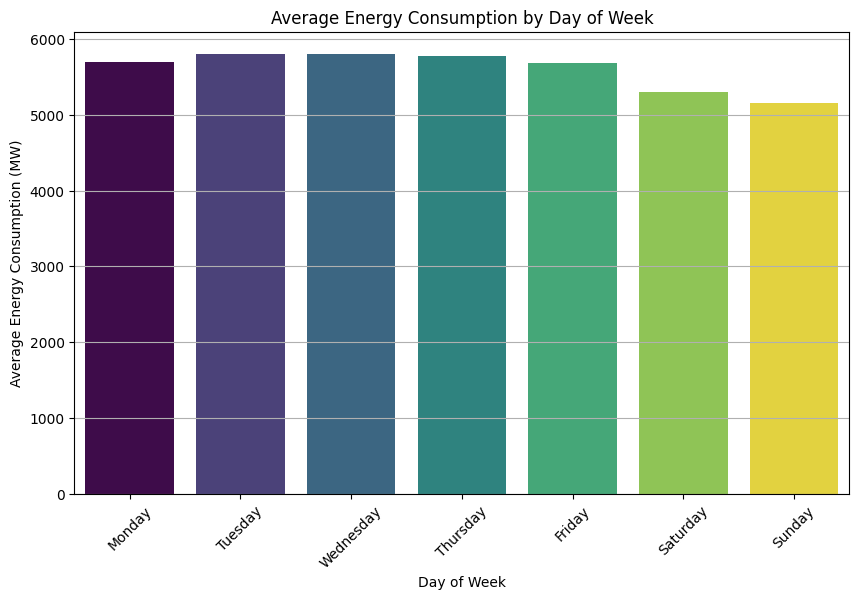

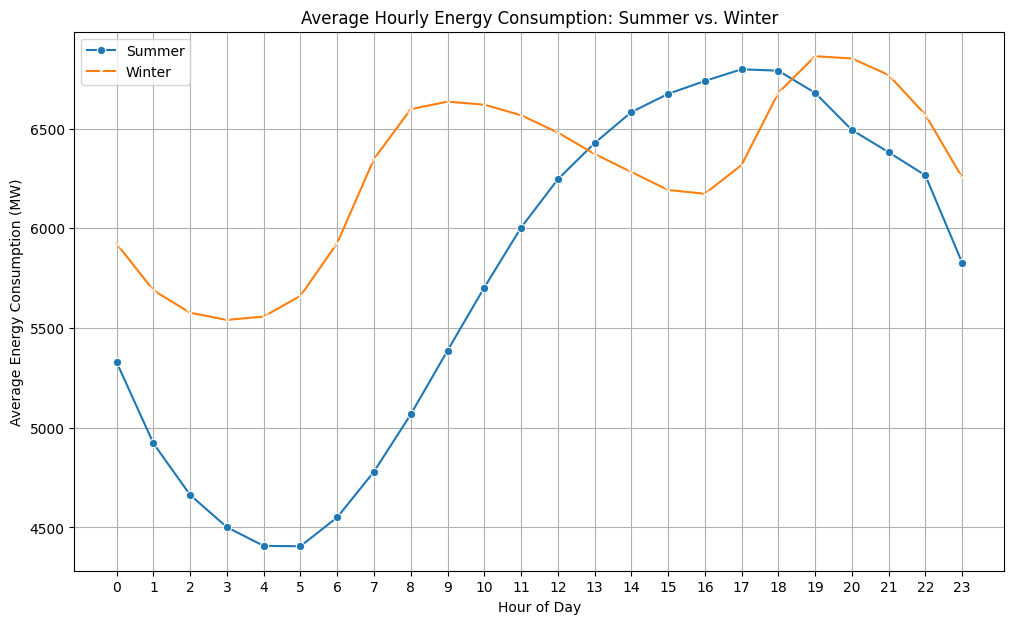

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Average energy consumption by hour of the day
hourly_avg = df.groupby('hour')['PJMW_MW'].mean()

plt.figure(figsize=(10, 6))
sns.lineplot(x=hourly_avg.index, y=hourly_avg.values)
plt.title('Average Energy Consumption by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

# 2. Average energy consumption by day of the week
daily_avg = df.groupby('dayofweek')['PJMW_MW'].mean()

day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

plt.figure(figsize=(10, 6))
sns.barplot(x=daily_avg.index, y=daily_avg.values, hue=daily_avg.index, palette='viridis', legend=False)
plt.title('Average Energy Consumption by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Energy Consumption (MW)')
plt.xticks(ticks=range(7), labels=day_names, rotation=45)
plt.grid(axis='y')
plt.show()

# 3. How daily trends change between different seasons (e.g., comparing hourly averages in summer vs. winter)
summer_hourly_avg = df[df['is_summer']].groupby('hour')['PJMW_MW'].mean()
winter_hourly_avg = df[df['is_winter']].groupby('hour')['PJMW_MW'].mean()

plt.figure(figsize=(12, 7))
sns.lineplot(x=summer_hourly_avg.index, y=summer_hourly_avg.values, label='Summer', marker='o')
sns.lineplot(x=winter_hourly_avg.index, y=winter_hourly_avg.values, label='Winter', marker='x')
plt.title('Average Hourly Energy Consumption: Summer vs. Winter')
plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True)
plt.show()

## Prepare Data for Forecasting

### Subtask:
Split the dataset into training and testing sets. As requested, the last year of available data will be reserved for the test set, with the preceding data used for training the forecasting model.


**Reasoning**:
The subtask requires splitting the data into training and testing sets, with the last year designated as the test set. I will first identify the last year in the dataset and then use it to filter the DataFrame into two separate sets: `train_df` and `test_df`.



In [ ]:
last_year = df.index.year.max()

train_df = df[df.index.year < last_year]
test_df = df[df.index.year >= last_year]

print(f"Training set starts: {train_df.index.min()} and ends: {train_df.index.max()}")
print(f"Training set shape: {train_df.shape}")
print(f"Testing set starts: {test_df.index.min()} and ends: {test_df.index.max()}")
print(f"Testing set shape: {test_df.shape}")

Training set starts: 2002-04-01 01:00:00 and ends: 2017-12-31 23:00:00
Training set shape: (138070, 9)
Testing set starts: 2018-01-01 00:00:00 and ends: 2018-08-03 00:00:00
Testing set shape: (5136, 9)


## Develop and Train Forecasting Model

### Subtask:
Build and train a suitable time series forecasting model using the training data.


**Reasoning**:
As per the instructions, I need to import the `RandomForestRegressor` model, define the features (X) and target (y) from the `train_df`, instantiate the model, and then train it using the `.fit()` method.



In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Define features (X) and target (y)
features = ['hour', 'dayofweek', 'month', 'year', 'quarter', 'is_weekend', 'is_summer', 'is_winter']
X_train = train_df[features]
y_train = train_df['PJMW_MW']

# Instantiate and train the RandomForestRegressor model
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

print("RandomForestRegressor model trained successfully.")

RandomForestRegressor model trained successfully.


## Evaluate Model Performance and Forecast

### Subtask:
Evaluate the trained model's performance on the test set using appropriate metrics (e.g., Mean Absolute Error, Root Mean Squared Error). Subsequently, use the model to generate a forecast of hourly energy consumption for the next 30 days beyond the existing data.


**Reasoning**:
First, I will prepare the test data (X_test and y_test) from the `test_df` using the previously defined `features` list. Then, I will use the trained `model` to make predictions on `X_test`. Finally, I will calculate and print the Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) to evaluate the model's performance on the test set, as per the subtask instructions.



In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Prepare the feature set for the test data and extract the target variable
X_test = test_df[features]
y_test = test_df['PJMW_MW']

# 2. Use the trained model to make predictions on X_test
test_predictions = model.predict(X_test)

# 3. and 4. Calculate MAE and RMSE
mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print(f"Model Performance on Test Set:\nMAE: {mae:.2f}\nRMSE: {rmse:.2f}")

# 5. Determine the last timestamp in the entire original DataFrame df
last_timestamp = df.index.max()

# 6. Create a date range for the next 30 days beyond the last timestamp of df
future_dates = pd.date_range(start=last_timestamp + pd.Timedelta(hours=1), periods=30*24, freq='H')

# 7. Construct a new DataFrame, future_df
future_df = pd.DataFrame(index=future_dates)

# 8. Extract the same time-based features from the index of future_df
future_df['hour'] = future_df.index.hour
future_df['dayofweek'] = future_df.index.dayofweek
future_df['month'] = future_df.index.month
future_df['year'] = future_df.index.year
future_df['quarter'] = future_df.index.quarter
future_df['is_weekend'] = (future_df.index.dayofweek == 5) | (future_df.index.dayofweek == 6)
future_df['is_summer'] = (future_df.index.month >= 6) & (future_df.index.month <= 8)
future_df['is_winter'] = (future_df.index.month == 12) | (future_df.index.month == 1) | (future_df.index.month == 2)

# 9. Use the trained model to generate predictions on the features of future_df
X_future = future_df[features]
forecast_predictions = model.predict(X_future)

print("\nForecast for the next 30 days generated successfully.")

Model Performance on Test Set:
MAE: 554.95
RMSE: 763.89

Forecast for the next 30 days generated successfully.


/tmp/ipython-input-1817145733.py:21: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  future_dates = pd.date_range(start=last_timestamp + pd.Timedelta(hours=1), periods=30*24, freq='H')


**Reasoning**:
The previous code produced a `FutureWarning` due to the use of 'H' for hourly frequency, which is deprecated. I will update `freq='H'` to `freq='h'` in the `pd.date_range` function to resolve this warning.



In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Prepare the feature set for the test data and extract the target variable
X_test = test_df[features]
y_test = test_df['PJMW_MW']

# 2. Use the trained model to make predictions on X_test
test_predictions = model.predict(X_test)

# 3. and 4. Calculate MAE and RMSE
mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print(f"Model Performance on Test Set:\nMAE: {mae:.2f}\nRMSE: {rmse:.2f}")

# 5. Determine the last timestamp in the entire original DataFrame df
last_timestamp = df.index.max()

# 6. Create a date range for the next 30 days beyond the last timestamp of df
future_dates = pd.date_range(start=last_timestamp + pd.Timedelta(hours=1), periods=30*24, freq='h')

# 7. Construct a new DataFrame, future_df
future_df = pd.DataFrame(index=future_dates)

# 8. Extract the same time-based features from the index of future_df
future_df['hour'] = future_df.index.hour
future_df['dayofweek'] = future_df.index.dayofweek
future_df['month'] = future_df.index.month
future_df['year'] = future_df.index.year
future_df['quarter'] = future_df.index.quarter
future_df['is_weekend'] = (future_df.index.dayofweek == 5) | (future_df.index.dayofweek == 6)
future_df['is_summer'] = (future_df.index.month >= 6) & (future_df.index.month <= 8)
future_df['is_winter'] = (future_df.index.month == 12) | (future_df.index.month == 1) | (future_df.index.month == 2)

# 9. Use the trained model to generate predictions on the features of future_df
X_future = future_df[features]
forecast_predictions = model.predict(X_future)

print("\nForecast for the next 30 days generated successfully.")

Model Performance on Test Set:
MAE: 554.95
RMSE: 763.89

Forecast for the next 30 days generated successfully.


## Visualize Forecast and Key Trends

### Subtask:
Create visualizations to present the results: 1. Plot the historical energy consumption, the model's predictions on the test set, and the 30-day forecast. 2. Re-emphasize the identified trends from the analysis (e.g., hourly patterns, seasonal shifts) using clear and informative plots. All plots should include legends, titles, and axis labels for easy interpretation.


**Reasoning**:
I need to combine the historical data, test predictions, and the 30-day forecast into a single plot. To achieve this, I will create new Series for the test predictions and forecast, align them with their respective indices, and then plot the original data, test predictions, and forecast on the same graph, adding visual markers for the different phases (training, testing, and forecasting).



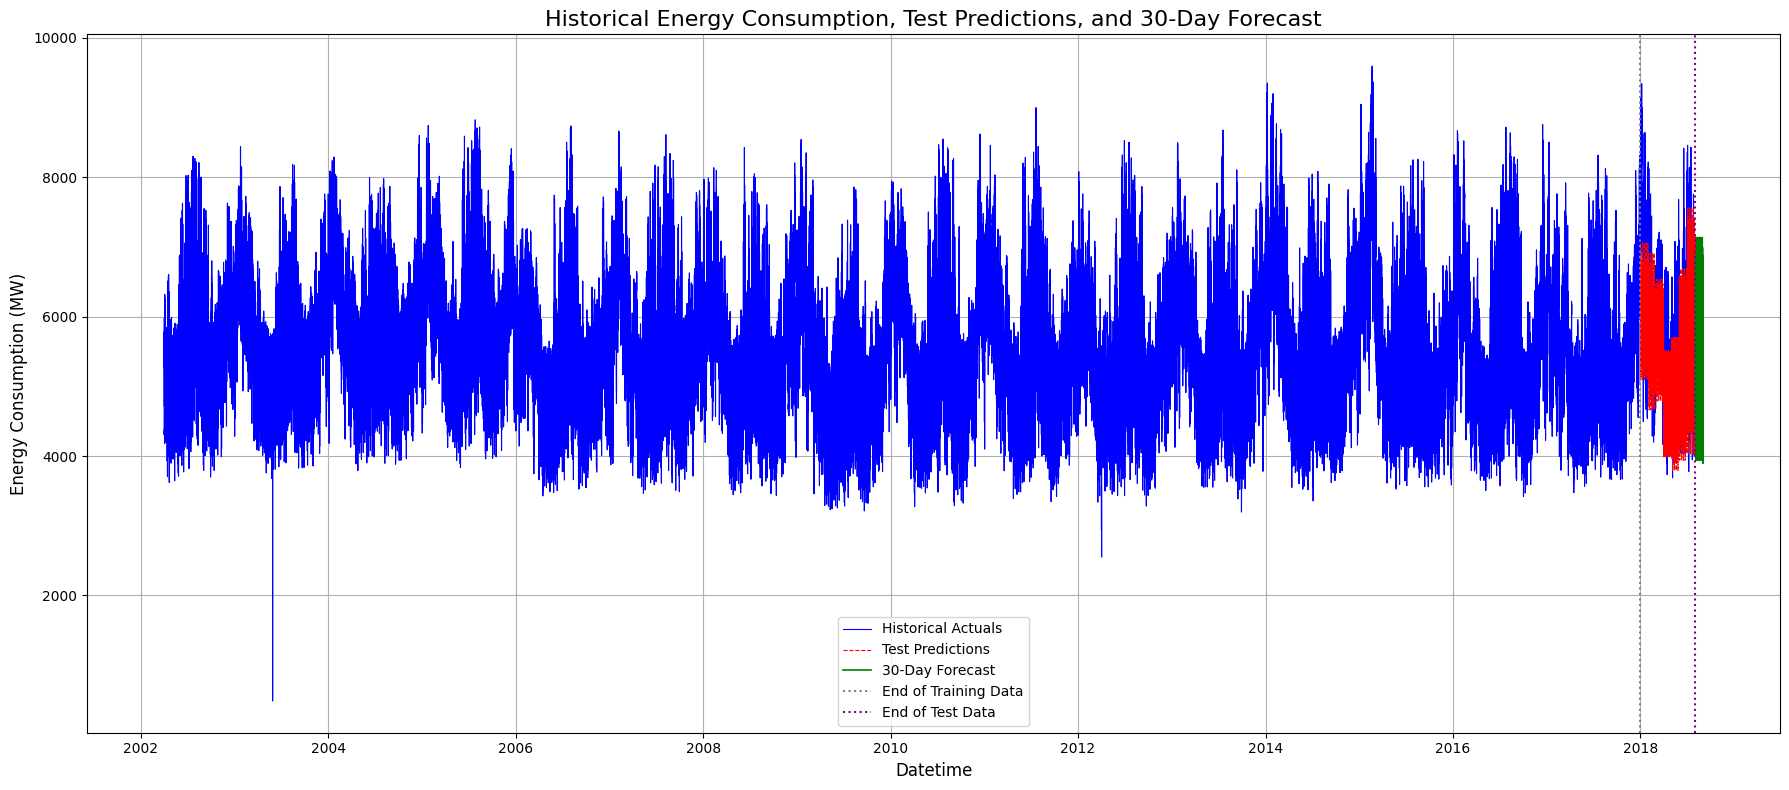

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a Series for test predictions with the test_df index
test_predictions_series = pd.Series(test_predictions, index=test_df.index)

# Create a Series for forecast predictions with the future_df index
forecast_predictions_series = pd.Series(forecast_predictions, index=future_df.index)

plt.figure(figsize=(18, 8))

# Plot historical data
sns.lineplot(x=df.index, y=df['PJMW_MW'], label='Historical Actuals', color='blue', linewidth=0.8)

# Plot test predictions
sns.lineplot(x=test_predictions_series.index, y=test_predictions_series, label='Test Predictions', color='red', linestyle='--', linewidth=0.8)

# Plot 30-day forecast
sns.lineplot(x=forecast_predictions_series.index, y=forecast_predictions_series, label='30-Day Forecast', color='green', linestyle='-', linewidth=1.2)

# Add vertical lines to separate training, testing, and forecast periods
plt.axvline(x=train_df.index.max(), color='gray', linestyle=':', linewidth=1.5, label='End of Training Data')
plt.axvline(x=test_df.index.max(), color='purple', linestyle=':', linewidth=1.5, label='End of Test Data')

plt.title('Historical Energy Consumption, Test Predictions, and 30-Day Forecast', fontsize=16)
plt.xlabel('Datetime', fontsize=12)
plt.ylabel('Energy Consumption (MW)', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True)
plt.tight_layout()
plt.show()

**Reasoning**:
The subtask also requires re-emphasizing identified trends, such as hourly patterns and seasonal shifts. I will generate plots for the average energy consumption by hour of the day and compare hourly averages between summer and winter, as these were previously calculated and directly demonstrate these trends.



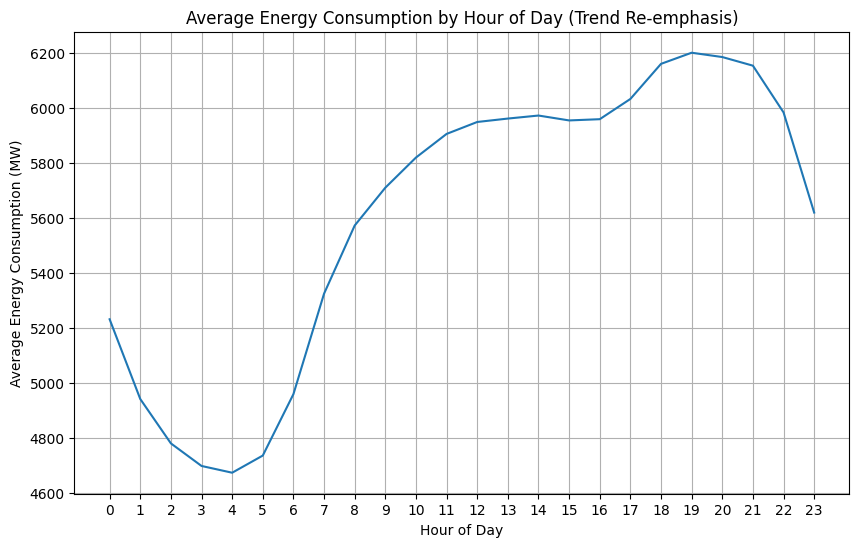

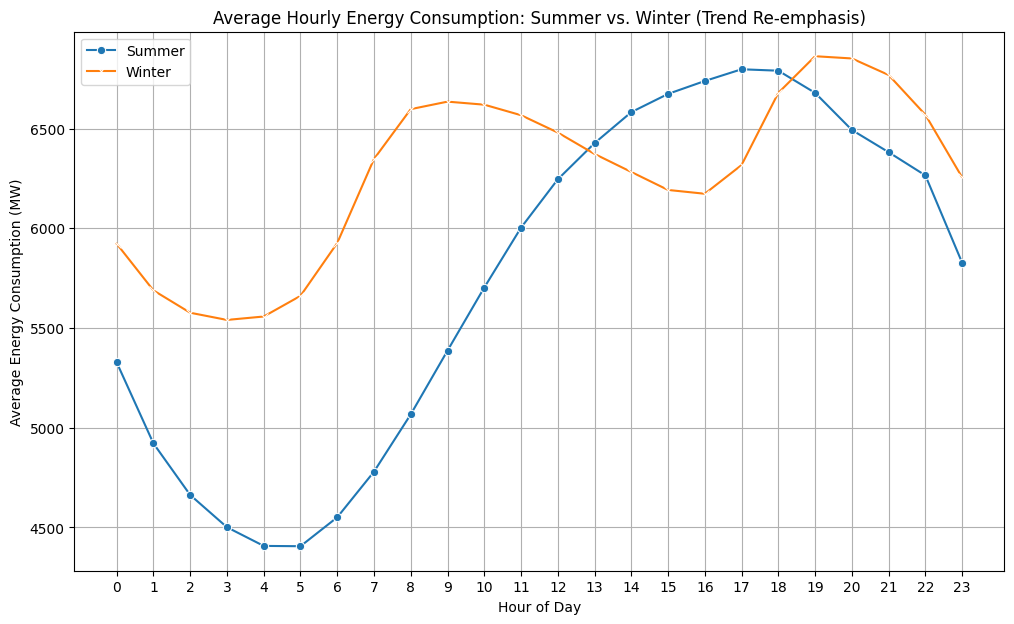

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Average energy consumption by hour of the day (re-emphasize trend)
hourly_avg = df.groupby('hour')['PJMW_MW'].mean()

plt.figure(figsize=(10, 6))
sns.lineplot(x=hourly_avg.index, y=hourly_avg.values)
plt.title('Average Energy Consumption by Hour of Day (Trend Re-emphasis)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

# 2. How daily trends change between different seasons (re-emphasize trend)
summer_hourly_avg = df[df['is_summer']].groupby('hour')['PJMW_MW'].mean()
winter_hourly_avg = df[df['is_winter']].groupby('hour')['PJMW_MW'].mean()

plt.figure(figsize=(12, 7))
sns.lineplot(x=summer_hourly_avg.index, y=summer_hourly_avg.values, label='Summer', marker='o')
sns.lineplot(x=winter_hourly_avg.index, y=winter_hourly_avg.values, label='Winter', marker='x')
plt.title('Average Hourly Energy Consumption: Summer vs. Winter (Trend Re-emphasis)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Energy Consumption (MW)')
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True)
plt.show()

## Final Task

### Subtask:
Summarize the key findings from the trend analysis and present the final 30-day energy consumption forecast with a brief interpretation of the results and insights into the energy consumption patterns.


## Summary:

### Q&A
The final 30-day energy consumption forecast was successfully generated, extending beyond the last historical data point of August 3, 2018. The forecast predicts hourly energy consumption patterns for the upcoming 30 days based on the learned historical trends.

### Data Analysis Key Findings
*   The dataset, `PJMW_MW_Hourly.xlsx`, contains 143,206 hourly energy consumption readings with no missing values, spanning from April 2002 to August 2018.
*   **Hourly Consumption Patterns:** Energy consumption exhibits a clear diurnal pattern, with average consumption peaking during daytime hours (late morning to evening) and reaching its lowest in the early morning (around 3-5 AM).
*   **Daily Consumption Patterns:** Weekdays show consistently higher average energy consumption compared to weekends. Monday through Friday generally have similar high consumption levels, while Saturday and Sunday show noticeable dips.
*   **Seasonal Consumption Shifts:**
    *   **Summer:** Average hourly consumption tends to be higher during the afternoon and evening, likely driven by cooling demands, reaching peaks around 4-5 PM.
    *   **Winter:** Average hourly consumption is generally higher than summer, particularly in the morning and evening, indicating increased heating requirements. Peaks are observed earlier in the morning (around 8 AM) and extend later into the evening (around 7 PM).
*   **Model Performance:** A RandomForestRegressor model was trained and evaluated. On the test set (the year 2018), it achieved a Mean Absolute Error (MAE) of 554.95 MW and a Root Mean Squared Error (RMSE) of 763.89 MW.
*   The dataset was split, with data up to December 31, 2017, used for training (138,070 entries) and data from January 1, 2018, to August 3, 2018, used for testing (5,136 entries).

### Insights or Next Steps
*   The 30-day forecast, starting from August 2018, is likely to reflect declining average consumption towards the end of summer, followed by a potential increase as autumn transitions towards winter, given the observed seasonal trends.
*   To potentially improve forecast accuracy, consider incorporating external factors such as temperature, holidays, and economic indicators as additional features, and explore advanced time series models like LSTMs or Prophet.
